# Predicción de recompra a 60 días: The Look - Juan Ignacio Ureta

**Objetivo:** identificar clientes con alta probabilidad de volver a comprar (una nueva orden) dentro de los 60 días posteriores a su primera compra.

**Flujo:** controles de calidad → tabla base en BigQuery → análisis exploratorio → modelo vs. referencia simple → predicciones.

**Cómo ejecutar:** Entorno de ejecución → Ejecutar todo (pide autenticarse con la cuenta de Google con acceso a BigQuery). Los parámetros (fecha de corte, horizonte) están en `CONFIG`.

In [13]:
from google.colab import auth
auth.authenticate_user()

In [14]:
from google.cloud import bigquery
client = bigquery.Client(project="bussiness-case-tyc")

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Controles de calidad de los datos
Antes de construir la base se revisan los estados de orden y la integridad de las claves (`order_id`, `user_id`, `product_id`).
**Decisión:** se excluye solo `Cancelled` (15% de las órdenes); el resto son compras reales.

In [16]:
from IPython.display import display

SRC = "bussiness-case-tyc.bussiness_case_ecommerce"

QUERY_ESTADOS = f"""
SELECT status, COUNT(*) AS n
FROM `{SRC}.orders`
GROUP BY 1 ORDER BY 2 DESC
"""

QUERY_CHECKS = f"""
SELECT 'orders duplicadas por order_id' AS check_name,
       COUNT(*) - COUNT(DISTINCT order_id) AS n
FROM `{SRC}.orders`
UNION ALL
SELECT 'orders con claves o fecha nulas',
       COUNTIF(user_id IS NULL OR created_at IS NULL OR order_id IS NULL)
FROM `{SRC}.orders`
UNION ALL
SELECT 'orders sin usuario en users', COUNT(*)
FROM `{SRC}.orders` o
LEFT JOIN `{SRC}.users` u ON u.id = o.user_id
WHERE u.id IS NULL
UNION ALL
SELECT 'orders sin items', COUNT(*)
FROM `{SRC}.orders` o
LEFT JOIN (SELECT DISTINCT order_id FROM `{SRC}.order_items`) oi ON oi.order_id = o.order_id
WHERE oi.order_id IS NULL
UNION ALL
SELECT 'items sin producto', COUNT(*)
FROM `{SRC}.order_items` oi
LEFT JOIN `{SRC}.products` p ON p.id = oi.product_id
WHERE p.id IS NULL
"""

print("Órdenes por estado:")
display(client.query(QUERY_ESTADOS).to_dataframe())
print("Controles de calidad (esperado: todos en 0):")
display(client.query(QUERY_CHECKS).to_dataframe())

Órdenes por estado:


,status,n
0,Shipped,37212
1,Complete,31157
2,Processing,24957
3,Cancelled,18714
4,Returned,12556


Controles de calidad (esperado: todos en 0):


,check_name,n
0,orders duplicadas por order_id,0
1,orders con claves o fecha nulas,0
2,orders sin usuario en users,0
3,orders sin items,0
4,items sin producto,0


## 2. Tabla base del modelo (SQL en BigQuery)
Una fila por cliente.
- **Primera compra:** primera orden válida por cliente (`ROW_NUMBER` ordenado por fecha y `order_id`).
- **Etiqueta:** 1 si existe otra *orden* (no ítem) dentro de los 60 días posteriores.
- **Sin fuga de información:** las variables usan solo datos hasta la primera compra; no se usan `shipped_at`, `delivered_at` ni `returned_at`, y los eventos web son solo anteriores a la compra.
- **Sin duplicados:** ítems y eventos se agregan antes de unir.
- **Clientes sin 60 días de historia:** se excluyen, porque su etiqueta aún no es confiable. La fecha de corte es configurable (`None` = última orden de los datos).
- **Reejecución:** `CREATE OR REPLACE TABLE` no duplica resultados, y `validate_base` detiene el proceso si algo falla.

In [17]:
import pandas as pd
from google.cloud import bigquery

CONFIG = {
    "project": "bussiness-case-tyc",
    "src_dataset": "bussiness_case_ecommerce",
    "dst_dataset": "juan_ureta",
    "dst_table": "base_modelo",
    "horizon_days": 60,
    "cutoff_date": None,   # None = fecha máxima de los datos; o un texto como "2024-12-31"
}

def get_cutoff(client, cfg):
    if cfg["cutoff_date"]:
        c = pd.Timestamp(cfg["cutoff_date"])
    else:
        q = f"SELECT MAX(created_at) AS m FROM `{cfg['project']}.{cfg['src_dataset']}.orders`"
        c = pd.Timestamp(client.query(q).to_dataframe()["m"].iloc[0])
    return c.tz_localize("UTC") if c.tzinfo is None else c.tz_convert("UTC")

def build_base_sql(cfg, cutoff):
    src = f"{cfg['project']}.{cfg['src_dataset']}"
    dst = f"{cfg['project']}.{cfg['dst_dataset']}.{cfg['dst_table']}"
    h = cfg["horizon_days"]
    cut = cutoff.strftime("%Y-%m-%d %H:%M:%S")
    return f"""
CREATE OR REPLACE TABLE `{dst}` AS
WITH params AS (
  SELECT TIMESTAMP('{cut}') AS max_ts
),
valid_orders AS (
  SELECT order_id, user_id, created_at
  FROM `{src}.orders`
  WHERE status != 'Cancelled'
    AND order_id IS NOT NULL AND user_id IS NOT NULL AND created_at IS NOT NULL
),
first_order AS (
  SELECT * EXCEPT(rn) FROM (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY created_at, order_id) AS rn
    FROM valid_orders
  ) WHERE rn = 1
),
label AS (
  SELECT f.user_id, f.order_id, f.created_at AS first_order_ts,
         IF(COUNT(o.order_id) > 0, 1, 0) AS repurchase_60d
  FROM first_order f
  LEFT JOIN valid_orders o
    ON o.user_id = f.user_id
   AND o.order_id != f.order_id
   AND o.created_at > f.created_at
   AND o.created_at <= TIMESTAMP_ADD(f.created_at, INTERVAL {h} DAY)
  GROUP BY 1, 2, 3
),
items_first AS (
  SELECT oi.order_id,
         COUNT(*) AS n_items,
         SUM(oi.sale_price) AS order_value,
         SUM(oi.sale_price - p.cost) AS order_margin,
         COUNT(DISTINCT p.category) AS n_categories,
         COUNT(DISTINCT p.brand) AS n_brands,
         ARRAY_AGG(p.department IGNORE NULLS ORDER BY oi.sale_price DESC LIMIT 1)[SAFE_OFFSET(0)] AS top_department,
         ARRAY_AGG(p.category IGNORE NULLS ORDER BY oi.sale_price DESC LIMIT 1)[SAFE_OFFSET(0)] AS top_category
  FROM `{src}.order_items` oi
  LEFT JOIN `{src}.products` p ON p.id = oi.product_id
  WHERE oi.order_id IN (SELECT order_id FROM first_order)
  GROUP BY 1
),
events_pre AS (
  SELECT f.user_id,
         COUNT(DISTINCT e.session_id) AS n_sessions_pre,
         COUNT(*) AS n_events_pre,
         COUNTIF(e.event_type = 'product') AS n_product_views_pre,
         COUNTIF(e.event_type = 'cart') AS n_cart_events_pre
  FROM first_order f
  JOIN `{src}.events` e
    ON e.user_id = f.user_id
   AND e.created_at < f.created_at
   AND e.event_type NOT IN ('purchase', 'cancel')
  GROUP BY 1
)
SELECT l.user_id, l.order_id AS first_order_id, l.first_order_ts, l.repurchase_60d,
       i.n_items, i.order_value, i.order_margin, i.n_categories, i.n_brands,
       i.top_department, i.top_category,
       u.age, u.gender, u.country, u.traffic_source,
       TIMESTAMP_DIFF(l.first_order_ts, u.created_at, DAY) AS days_signup_to_purchase,
       COALESCE(ev.n_sessions_pre, 0) AS n_sessions_pre,
       COALESCE(ev.n_events_pre, 0) AS n_events_pre,
       COALESCE(ev.n_product_views_pre, 0) AS n_product_views_pre,
       COALESCE(ev.n_cart_events_pre, 0) AS n_cart_events_pre
FROM label l
JOIN `{src}.users` u ON u.id = l.user_id
LEFT JOIN items_first i ON i.order_id = l.order_id
LEFT JOIN events_pre ev ON ev.user_id = l.user_id
CROSS JOIN params p
WHERE l.first_order_ts <= TIMESTAMP_SUB(p.max_ts, INTERVAL {h} DAY)
"""

def validate_base(client, cfg, cutoff):
    dst = f"{cfg['project']}.{cfg['dst_dataset']}.{cfg['dst_table']}"
    q = f"""SELECT COUNT(*) AS filas, COUNT(DISTINCT user_id) AS clientes,
                   COUNTIF(user_id IS NULL OR repurchase_60d IS NULL) AS nulos,
                   AVG(repurchase_60d) AS tasa, MAX(first_order_ts) AS max_t0
            FROM `{dst}`"""
    r = client.query(q).to_dataframe().iloc[0]
    limite = cutoff - pd.Timedelta(days=cfg["horizon_days"])
    assert r.filas == r.clientes, "Hay clientes duplicados"
    assert r.nulos == 0, "Hay nulos en la clave o en la etiqueta"
    assert 0 < r.tasa < 1, "Tasa de recompra fuera de rango"
    assert pd.Timestamp(r.max_t0) <= limite, "Hay clientes sin ventana completa"
    print(f"Validaciones OK | filas={r.filas} | tasa={r.tasa:.4f} | corte={cutoff}")

def run_pipeline(cfg=CONFIG):
    client = bigquery.Client(project=cfg["project"])
    cutoff = get_cutoff(client, cfg)
    client.query(build_base_sql(cfg, cutoff)).result()
    validate_base(client, cfg, cutoff)
    dst = f"{cfg['project']}.{cfg['dst_dataset']}.{cfg['dst_table']}"
    return client.query(f"SELECT * FROM `{dst}`").to_dataframe(), cutoff

df, cutoff = run_pipeline()
print(df.shape)

Validaciones OK | filas=63538 | tasa=0.0627 | corte=2025-02-14 19:31:25.006404+00:00
(63538, 20)


## 3. Análisis exploratorio
**Recompra por mes:** ronda 3-5% hasta 2023 y se acelera en 2024, hasta ~17% en diciembre. El promedio global (6.3%) esconde ese cambio.

Tasa de recompra global: 6.27%


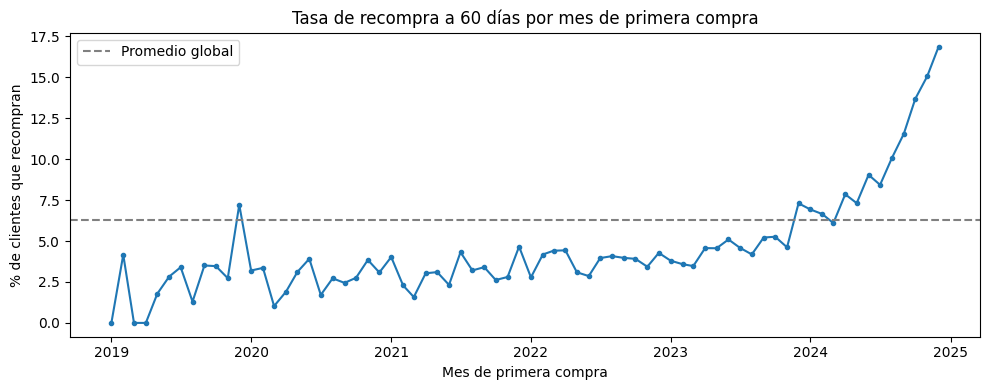

In [18]:
df["first_order_ts"] = pd.to_datetime(df["first_order_ts"])
df["mes"] = df["first_order_ts"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()

tasa_global = df["repurchase_60d"].mean()
print(f"Tasa de recompra global: {tasa_global:.2%}")

mensual = df.groupby("mes").agg(clientes=("user_id", "count"),
                                tasa=("repurchase_60d", "mean")).reset_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensual["mes"], mensual["tasa"] * 100, marker="o", markersize=3)
ax.axhline(tasa_global * 100, color="gray", linestyle="--", label="Promedio global")
ax.set_title("Tasa de recompra a 60 días por mes de primera compra")
ax.set_ylabel("% de clientes que recompran")
ax.set_xlabel("Mes de primera compra")
ax.legend()
plt.tight_layout()
plt.show()

**Días entre la primera y la segunda compra:** la mediana es de 205 días y solo el 23.9% de las segundas compras ocurre dentro de 60 días. La ventana de 60 días captura la recompra rápida.

count       23843.0
mean     324.454934
std      346.337305
min             0.0
25%            65.0
50%           205.0
75%           472.0
max          2118.0
Name: dias_entre_1_y_2, dtype: Float64
Segundas compras dentro de 60 días: 23.9%


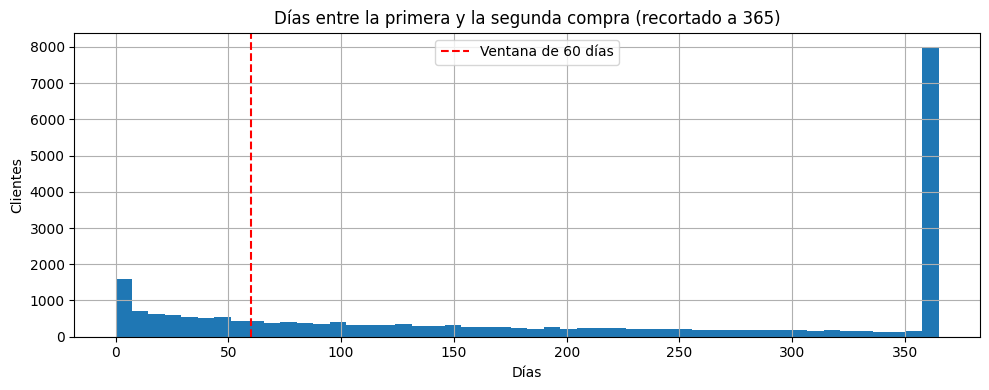

In [19]:
query_gaps = """
WITH ordenes AS (
  SELECT user_id, created_at,
         ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY created_at, order_id) AS rn
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE status != 'Cancelled'
)
SELECT a.user_id,
       TIMESTAMP_DIFF(b.created_at, a.created_at, DAY) AS dias_entre_1_y_2
FROM ordenes a
JOIN ordenes b ON a.user_id = b.user_id AND a.rn = 1 AND b.rn = 2
"""
gaps = client.query(query_gaps).to_dataframe()

print(gaps["dias_entre_1_y_2"].describe())
print(f"Segundas compras dentro de 60 días: {(gaps['dias_entre_1_y_2'] <= 60).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
gaps["dias_entre_1_y_2"].clip(upper=365).hist(bins=50, ax=ax)
ax.axvline(60, color="red", linestyle="--", label="Ventana de 60 días")
ax.set_title("Días entre la primera y la segunda compra (recortado a 365)")
ax.set_xlabel("Días")
ax.set_ylabel("Clientes")
ax.legend()
plt.tight_layout()
plt.show()

**Segmentos:** ni el departamento ni el canal de origen diferencian: todos rondan el 6%.

top_department  clientes  tasa_pct
           Men     31582      6.43
         Women     31956      6.12 

traffic_source  clientes  tasa_pct
      Facebook      3806      6.49
        Search     44555      6.29
       Organic      9432      6.24
       Display      2561      6.17
         Email      3184      5.97 



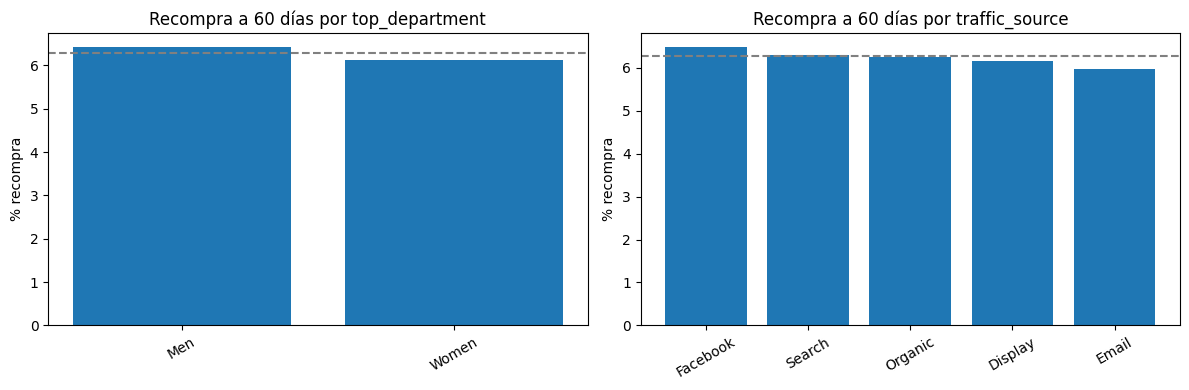

In [20]:
def tabla_segmento(col):
    t = (df.groupby(col)
           .agg(clientes=("user_id", "count"), tasa=("repurchase_60d", "mean"))
           .reset_index().sort_values("tasa", ascending=False))
    t["tasa_pct"] = (t["tasa"] * 100).round(2)
    return t

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["top_department", "traffic_source"]):
    t = tabla_segmento(col)
    print(t[[col, "clientes", "tasa_pct"]].to_string(index=False), "\n")
    ax.bar(t[col].astype(str), t["tasa"] * 100)
    ax.axhline(tasa_global * 100, color="gray", linestyle="--")
    ax.set_title(f"Recompra a 60 días por {col}")
    ax.set_ylabel("% recompra")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Variables numéricas:** `order_value`, `n_sessions_pre` y `age` no separan. `days_signup_to_purchase` sí: quien compra pronto tras registrarse recompra más, incluso dentro de cada año (en 2024: 19.8% vs. 3.2%). La relación se intensifica con el tiempo.

In [21]:
def tabla_cuartiles(col, q=4):
    s = pd.qcut(df[col], q=q, duplicates="drop")
    t = (df.groupby(s, observed=True)
           .agg(clientes=("user_id", "count"), tasa=("repurchase_60d", "mean"))
           .reset_index())
    t["tasa_pct"] = (t["tasa"] * 100).round(2)
    return t[[col, "clientes", "tasa_pct"]]

for col in ["order_value", "n_sessions_pre", "days_signup_to_purchase", "age"]:
    print(tabla_cuartiles(col).to_string(index=False), "\n")

       order_value  clientes  tasa_pct
     (0.019, 29.0]     15945      6.59
      (29.0, 55.0]     15937      6.25
   (55.0, 109.585]     15771      6.35
(109.585, 1830.89]     15885       5.9 

n_sessions_pre  clientes  tasa_pct
 (-0.001, 1.0]     42112      6.41
    (1.0, 2.0]     13699      6.02
   (2.0, 10.0]      7727      5.97 

days_signup_to_purchase  clientes  tasa_pct
         (0.999, 135.0]     15961     11.77
         (135.0, 356.0]     15838      6.57
         (356.0, 745.0]     15871      3.93
        (745.0, 2143.0]     15868       2.8 

           age  clientes  tasa_pct
(11.999, 26.0]     16191      6.21
  (26.0, 41.0]     16329      6.17
  (41.0, 56.0]     16118      6.33
  (56.0, 70.0]     14900      6.39 



In [22]:
df["anio"] = df["first_order_ts"].dt.year
df["q_dias"] = pd.qcut(df["days_signup_to_purchase"], 4,
                       labels=["Q1 compra pronto", "Q2", "Q3", "Q4 compra tarde"])

tasa = (df.pivot_table(index="anio", columns="q_dias", values="repurchase_60d",
                       aggfunc="mean", observed=True) * 100).round(2)
n = df.pivot_table(index="anio", columns="q_dias", values="user_id",
                   aggfunc="count", observed=True)

print("Tasa de recompra (%) por año y tramo:\n", tasa, "\n")
print("Clientes por año y tramo:\n", n)

Tasa de recompra (%) por año y tramo:
 q_dias  Q1 compra pronto     Q2    Q3  Q4 compra tarde
anio                                                  
2019                2.77    3.9  <NA>             <NA>
2020                3.29   2.51  2.69             <NA>
2021                3.75   3.05  2.89             3.09
2022                5.46   4.98  3.23             2.19
2023                8.23   5.63  4.02             2.59
2024               19.78  10.93  5.27             3.19 

Clientes por año y tramo:
 q_dias  Q1 compra pronto    Q2    Q3  Q4 compra tarde
anio                                                 
2019                 867   513  <NA>             <NA>
2020                1277  1715  1228             <NA>
2021                1548  2067  2766             1002
2022                2126  2648  3224             3061
2023                3185  3588  3908             5064
2024                6958  5307  4745             6741


## 4. Modelo y evaluación
- **Separación temporal:** se entrena con clientes antiguos y se prueba con los últimos 3 meses con etiqueta completa, con un hueco de 60 días entre ambos para evitar fuga.
- **Modelo:** regresión logística. **Referencia:** regla "compra pronto tras registrarse".
- **Métricas:** PR AUC, y precision, recall y F1 al contactar al 20% de clientes con mayor puntaje.

Train: 51,643 clientes | recompra 4.73%
Test : 7,642 clientes | recompra 14.56%

Métricas en test (contactando al 20% con mayor puntaje):


,PR AUC,Precision,Recall,F1
Regla simple,0.298,0.329,0.452,0.381
Regresión logística,0.268,0.308,0.423,0.357


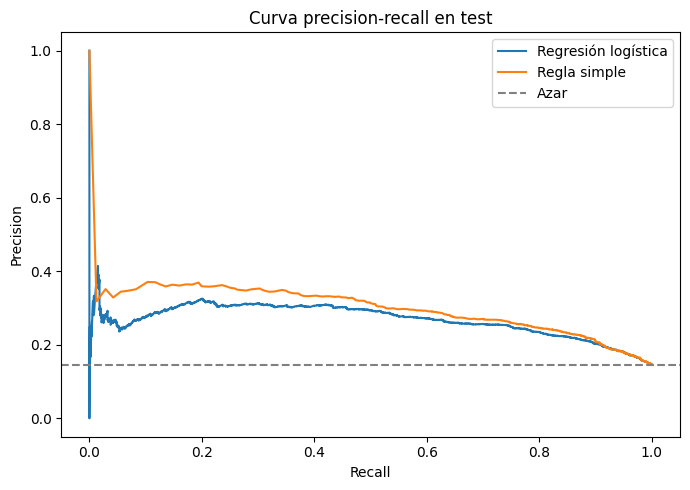

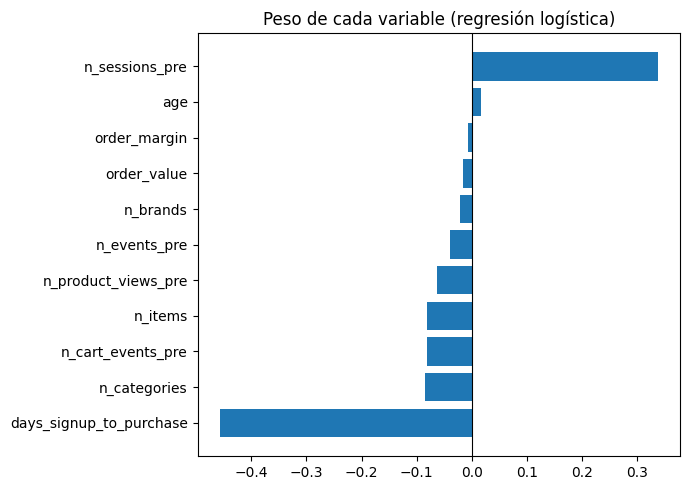

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, precision_score,
                             recall_score, f1_score, precision_recall_curve)

TARGET = "repurchase_60d"
FEATURES = ["n_items", "order_value", "order_margin", "n_categories", "n_brands", "age",
            "days_signup_to_purchase", "n_sessions_pre", "n_events_pre",
            "n_product_views_pre", "n_cart_events_pre"]
TEST_MONTHS = 3    # los últimos 3 meses de clientes con etiqueta completa
GAP_DAYS = 60      # hueco entre train y test para evitar fuga
TOP_FRAC = 0.20    # contactamos al 20% con mayor puntaje

def split_temporal(df):
    t = pd.to_datetime(df["first_order_ts"])
    test_start = t.max() - pd.DateOffset(months=TEST_MONTHS)
    train_end = test_start - pd.Timedelta(days=GAP_DAYS)
    return df[t < train_end], df[t >= test_start]

def metricas(y, score):
    k = int(len(y) * TOP_FRAC)
    pred = np.zeros(len(y), dtype=int)
    pred[np.argsort(-score)[:k]] = 1
    return {"PR AUC": average_precision_score(y, score),
            "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred)}

train, test = split_temporal(df)
X_train = train[FEATURES].astype("float64")
X_test = test[FEATURES].astype("float64")
y_train = train[TARGET].astype(int).values
y_test = test[TARGET].astype(int).values
print(f"Train: {len(train):,} clientes | recompra {y_train.mean():.2%}")
print(f"Test : {len(test):,} clientes | recompra {y_test.mean():.2%}\n")

modelo = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(max_iter=1000))
modelo.fit(X_train, y_train)
p_test = modelo.predict_proba(X_test)[:, 1]

dias = test["days_signup_to_purchase"].astype("float64")
score_regla = -dias.fillna(dias.median()).values   # menos días = más puntaje

tabla = pd.DataFrame({"Regla simple": metricas(y_test, score_regla),
                      "Regresión logística": metricas(y_test, p_test)}).T
print(f"Métricas en test (contactando al {TOP_FRAC:.0%} con mayor puntaje):")
display(tabla.round(3))

# Gráfico 4: curva precision-recall
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, s in [("Regresión logística", p_test), ("Regla simple", score_regla)]:
    pr, rc, _ = precision_recall_curve(y_test, s)
    ax.plot(rc, pr, label=nombre)
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Azar")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva precision-recall en test")
ax.legend()
plt.tight_layout()
plt.show()

# Gráfico 5: qué variables pesan más
coefs = pd.Series(modelo[-1].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(coefs.index, coefs.values)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Peso de cada variable (regresión logística)")
plt.tight_layout()
plt.show()

**Resultado:** al contactar al 20% con mayor puntaje, el modelo captura el 42% de quienes recompran (el azar, 20%). La regla simple obtiene un resultado similar, un poco mejor (45%). La señal es débil y cambia con el tiempo.

## 5. Predicciones
Genera `user_id` y probabilidad de recompra, con validaciones simples. El archivo se sobrescribe al reejecutar, por lo que no hay duplicados.

In [24]:
def generar_predicciones(test, probs, cutoff, ruta="predicciones_muestra.csv"):
    pred = pd.DataFrame({"user_id": test["user_id"].values,
                         "prob_recompra_60d": probs})
    # Validaciones simples
    assert pred["user_id"].is_unique, "Hay clientes repetidos"
    assert pred["prob_recompra_60d"].between(0, 1).all(), "Probabilidades fuera de rango"
    pred["fecha_corte"] = cutoff.strftime("%Y-%m-%d")
    # Al re-ejecutar, el archivo se sobrescribe: no se duplican resultados
    pred.sort_values("prob_recompra_60d", ascending=False).to_csv(ruta, index=False)
    return pred

pred = generar_predicciones(test, p_test, cutoff)
print(f"{len(pred):,} predicciones guardadas en predicciones_muestra.csv")
pred.head()

7,642 predicciones guardadas en predicciones_muestra.csv


,user_id,prob_recompra_60d,fecha_corte
0,40434,0.071049,2025-02-14
1,26401,0.067357,2025-02-14
2,31555,0.073806,2025-02-14
3,66213,0.072846,2025-02-14
4,86392,0.069854,2025-02-14


## 6. Limitaciones y mejoras
- La relación con la recompra cambia en el tiempo (mucho más fuerte en 2024), por lo que el modelo entrenado con años anteriores subestima las probabilidades.
- La diferencia entre el modelo y la regla es pequeña y no se probó estadísticamente.
- El modelo usa solo variables numéricas.
- La ventana de 60 días captura solo el 23.9% de las segundas compras.
- **Mejoras:** probar horizontes de 90 y 180 días, más variables de comportamiento, y reentrenar con frecuencia.

## 7. Optimización con más volumen
- **BigQuery:** particionar por fecha y clusterizar por `user_id`, seleccionar solo las columnas necesarias, filtrar `events` a los clientes y fechas relevantes antes de unir, y materializar la tabla base. En producción, procesar solo clientes nuevos (incremental).
- **Snowflake:** claves de clustering sobre `user_id` y fecha, `QUALIFY ROW_NUMBER() ... = 1` para la primera orden, y un warehouse dimensionado por carga.